<div style="background:linear-gradient(120deg,#1b3a2f 0%,#2f6f4e 100%);padding:34px 30px;border-radius:10px;color:white;font-family:'Segoe UI',system-ui,sans-serif;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:3px;opacity:.85;text-transform:uppercase;">Trabajo Práctico Integrador · Minería de Datos</div><div style="font-family:Georgia,serif;font-size:30px;font-weight:700;margin-top:6px;">Etapa 2b — Taller de limpieza de datos sucios</div><div style="font-size:18px;margin-top:12px;opacity:.95;">Aprender a limpiar con datos <b>reales</b>: el registro oficial de India (Dataset B) y un set clásico chico para practicar</div></div>

## 🎯 Para qué sirve este taller

En la Etapa 1, el Dataset A (el de las 22 cultivos) llegó **perfecto**: sin nulos, sin duplicados, balanceado. Eso es ideal para entrenar modelos, pero **no enseña lo más importante del oficio**: en un proyecto real, entre el 60 % y el 80 % del tiempo se va en limpiar datos.

Este taller usa **datos reales y sucios** para que veas con tus propios ojos:
1. **qué** problemas aparecen (y cómo detectarlos),
2. **cómo** se arreglan con pocas líneas de código,
3. **qué pasa si no los arreglás** (resultados que parecen correctos pero están mal).

> ✅ **Todo está medido "antes y después"**: no se limpia por intuición, se limpia y se comprueba.

## 🧪 Los dos datasets de práctica
| | Parte A | Parte B |
|---|---|---|
| **Dato** | Producción agrícola oficial de India (Dataset B de tu TP) | Pasajeros del Titanic (clásico mundial para aprender limpieza) |
| **Tamaño** | 246.091 filas | 891 filas |
| **Qué ejercita** | Texto, nombres, totales, duplicados, faltantes, unidades | Faltantes (cómo elegir cómo completarlos) y texto útil |
| **Nivel** | Completo, pero explicado paso a paso | Rápido (15 min) |

## 🧰 La receta de limpieza en 9 pasos (la que vamos a seguir)
| # | Síntoma | Herramienta | Por qué importa |
|---|---|---|---|
| 1 | Espacios invisibles en el texto | `.str.strip()` | Un filtro `== "Kharif"` devuelve **0 filas** sin avisar |
| 2 | Typos y sinónimos | diccionario + `.replace()` | "Paddy" y "Rice" se cuentan como cultivos distintos |
| 3 | Filas de totales mezcladas con el detalle | `.str.contains()` | Doble conteo |
| 4 | Duplicados que aparecen *al arreglar* lo anterior | `.duplicated()` | Superficie inflada |
| 5 | Valores faltantes | diagnóstico + imputación **medida** | Sesgo y filas perdidas |
| 6 | Ceros sospechosos | banderas (`flags`) | ¿Cero real o dato faltante? |
| 7 | Unidades mezcladas | revisar la distribución | Rendimientos de 40.000 "t/ha" |
| 8 | Columnas derivadas | `Rendimiento = Producción / Área` | Permite comparar entre distritos |
| 9 | **Bitácora** | tabla de cambios | Todo cambio queda documentado |

### 📚 Fuentes
- **Dataset B:** Ministerio de Agricultura de India (`data.gov.in`), copia pública en Kaggle (`abhinand05/crop-production-in-india`). Licencia: Government Open Data License – India. **Archivo sin modificar:** `crop_production_india.csv`.
- **Titanic:** datos históricos públicos del naufragio (1912), distribuidos por *Data Science Dojo* en GitHub.

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Preparación</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Herramientas y una bitácora de cambios</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Cada paso anota cuántas filas había antes y después</div></div>

<div style="border-left:6px solid #1565c0;background:#eef5fc;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15px;line-height:1.6;color:#14181a;"><b>📂 Dónde van los archivos (versión VS Code)</b><br>Los CSV están en la carpeta <code>datos/</code> junto a este notebook. Las celdas de carga <b>aceptan los archivos tanto en su versión original (inglés) como ya traducidos al castellano</b>, y lo que el notebook genera se guarda en <code>salida/</code>. <b>Este taller necesita además el archivo CRUDO <code>crop_production_india.csv</code> (ponelo en <code>datos/</code>).</b> Si algo falla, ejecutá primero <code>python verificar_proyecto.py</code>.</div>

In [1]:
import os, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore"); sns.set_style("whitegrid")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.3f}".format
SEED = 42

# Si estás en Colab y falta el archivo crudo, te pide subirlo
from pathlib import Path

# --- Ubicación de archivos: busca en datos/, en la carpeta actual y en la carpeta superior ---
def ruta(nombre, alternativas=(), obligatorio=True):
    """Devuelve la ruta del primer archivo que exista (acepta nombres alternativos)."""
    for n in (nombre, *alternativas):
        for carpeta in (Path("datos"), Path("."), Path("../datos"), Path("..")):
            if (carpeta / n).exists():
                return carpeta / n
    if obligatorio:
        raise FileNotFoundError(
            f"No encuentro '{nombre}'.\n  Carpeta de trabajo actual: {Path.cwd()}\n"
            "  → Abrí la carpeta COMPLETA del proyecto en VS Code (File > Open Folder) "
            "y verificá que exista la subcarpeta datos/ (podés correr verificar_proyecto.py).")
    return None

SALIDA = Path("salida"); SALIDA.mkdir(exist_ok=True)

# Archivo CRUDO (sin limpiar) de producción agrícola de India: 246.091 filas, columnas State_Name, District_Name, Crop_Year, Season, Crop, Area, Production
RUTA_CRUDO = ruta("crop_production_india.csv", ("crop_production.csv",), obligatorio=False)
if RUTA_CRUDO is None:
    raise FileNotFoundError(
        "Falta el archivo CRUDO 'crop_production_india.csv' (el mismo que usaste en la Etapa 1, 246.091 filas, 7 columnas).\n"
        "→ Copialo a la carpeta datos/ con ese nombre (si lo tenés como 'crop_production.csv' también se acepta) y volvé a ejecutar.\n"
        "  Este es el único archivo que no puede generarse desde los demás: el taller necesita los datos SUCIOS originales.")
print("Archivo crudo:", RUTA_CRUDO)

# ---- Bitácora: cada paso de limpieza se anota acá ----
bitacora = []
def anotar(paso, que_hice, filas_antes, filas_despues, afectadas=None):
    bitacora.append({"Paso": paso, "Qué se hizo": que_hice, "Filas antes": filas_antes,
                     "Filas después": filas_despues, "Afectadas (celdas/filas)": afectadas if afectadas is not None else abs(filas_antes - filas_despues)})

# ---- Navaja suiza: auditoría rápida de CUALQUIER tabla ----
def auditar(df, nombre="tabla"):
    print(f"📋 {nombre}: {df.shape[0]:,} filas × {df.shape[1]} columnas")
    print(f"   Filas duplicadas exactas : {df.duplicated().sum():,}")
    nulos = df.isna().sum(); nulos = nulos[nulos > 0]
    print("   Columnas con nulos       :", {c: f"{v:,} ({v/len(df):.1%})" for c, v in nulos.items()} or "ninguna")
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            s = df[c].dropna().astype(str)
            con_esp = (s != s.str.strip()).sum()
            if con_esp: print(f"   ⚠️ '{c}': {con_esp:,} valores con espacios al inicio/final")
    num = df.select_dtypes("number")
    neg = {c: int((num[c] < 0).sum()) for c in num.columns if (num[c] < 0).any()}
    print("   Columnas con negativos   :", neg or "ninguna")
print("Listo ✅")

Listo ✅


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><code>auditar()</code> es tu <b>navaja suiza</b>: la podés copiar a cualquier proyecto y aplicarla a cualquier tabla como primer paso. Detecta duplicados, nulos, espacios invisibles y números negativos en una sola llamada.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte A</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Producción agrícola oficial de India</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Un archivo real, sin curar, de un ministerio</div></div>

### 🔍 Paso 0 · Primer vistazo (antes de tocar nada)

In [2]:
try:
    raw = pd.read_csv(RUTA_CRUDO)
except UnicodeDecodeError:
    raw = pd.read_csv(RUTA_CRUDO, encoding="latin-1")
TRADUCCION = {"State_Name": "Estado", "District_Name": "Distrito", "Crop_Year": "Anio",
              "Season": "Temporada", "Crop": "Cultivo", "Area": "Area_ha", "Production": "Produccion_ton"}
df = raw.rename(columns=TRADUCCION).copy()          # trabajamos sobre una COPIA: el original no se toca nunca
TEXTO = ["Estado", "Distrito", "Temporada", "Cultivo"]
auditar(df, "Producción agrícola India (crudo)")
df.head()

📋 Producción agrícola India (crudo): 246,091 filas × 7 columnas


   Filas duplicadas exactas : 0
   Columnas con nulos       : {'Produccion_ton': '3,730 (1.5%)'}
   ⚠️ 'Estado': 7,283 valores con espacios al inicio/final


   ⚠️ 'Temporada': 246,091 valores con espacios al inicio/final
   ⚠️ 'Cultivo': 1,985 valores con espacios al inicio/final
   Columnas con negativos   : ninguna


,Estado,Distrito,Anio,Temporada,Cultivo,Area_ha,Produccion_ton
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,"1,254.000","2,000.000"
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.000,1.000
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.000,321.000
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.000,641.000
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.000,165.000


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>A simple vista la tabla parece normal. La auditoría marca lo que el ojo no ve: <b>espacios invisibles</b> y <b>3.730 producciones faltantes</b>. Recién estamos empezando.</div>

### 1️⃣ Espacios invisibles: el error que no da error

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Mirá la columna <code>Temporada</code>: dice <code>"Kharif     "</code> (con espacios de relleno). Para una persona es lo mismo que <code>"Kharif"</code>; para la computadora es un texto distinto. <b>No tira ningún error: simplemente devuelve resultados incompletos.</b></div>

In [3]:
print("Valores de Temporada (entre corchetes para ver los espacios):")
print([f"[{x}]" for x in df.Temporada.unique()])
print("\nFilas con Temporada == 'Kharif':", (df.Temporada == "Kharif").sum(), " ← ¡CERO, y hay miles de Kharif!")

antes = df.copy()
for c in TEXTO:
    df[c] = df[c].str.strip().str.replace(r"\s+", " ", regex=True)      # saca espacios de los bordes y dobles espacios
print("\nDespués de limpiar:", (df.Temporada == "Kharif").sum(), "filas Kharif")
afectadas = sum((antes[c] != df[c]).sum() for c in TEXTO)
anotar("1. Espacios", "strip() y espacios dobles en 4 columnas de texto", len(antes), len(df), afectadas)

Valores de Temporada (entre corchetes para ver los espacios):
['[Kharif     ]', '[Whole Year ]', '[Autumn     ]', '[Rabi       ]', '[Summer     ]', '[Winter     ]']

Filas con Temporada == 'Kharif': 0  ← ¡CERO, y hay miles de Kharif!



Después de limpiar: 95951 filas Kharif


<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br>Este es el defecto <b>más peligroso</b> porque es silencioso: un <code>groupby</code>, un filtro o un <code>merge</code> darían resultados <i>incompletos</i> sin avisar. Por eso se limpia primero el texto, antes que cualquier otra cosa.</div>

### 2️⃣ Typos y sinónimos en los nombres de cultivos

In [4]:
print("Cultivos distintos antes:", df.Cultivo.nunique())
sospechosos = ["Arcanut (Processed)", "Atcanut (Raw)", "Pome Granet", "Pump Kin", "Paddy", "Rice", "Kapas", "Cotton(lint)"]
display(df[df.Cultivo.isin(sospechosos)].Cultivo.value_counts().to_frame("filas"))

Cultivos distintos antes: 124


,filas
Cultivo,
Rice,15104
Cotton(lint),4518
Paddy,479
Pump Kin,93
Pome Granet,66
Arcanut (Processed),20
Atcanut (Raw),20
Kapas,12


<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br><code>Pome Granet</code> es <i>Pomegranate</i> (granada) mal escrito; <code>Pump Kin</code> es <i>Pumpkin</i> (zapallo); <code>Paddy</code> es el arroz con cáscara, o sea <i>Rice</i>; <code>Kapas</code> y <code>Cotton(lint)</code> son algodón. Un programa no puede adivinar esto: <b>hace falta conocimiento del tema</b>. Por eso se resuelve con un <b>diccionario</b> armado por una persona.</div>

In [5]:
NORMALIZA_CULTIVO = {
    "Paddy": "Rice", "Kapas": "Cotton", "Cotton(lint)": "Cotton",
    "Arcanut (Processed)": "Arecanut", "Atcanut (Raw)": "Arecanut",
    "Cashewnut Processed": "Cashewnut", "Cashewnut Raw": "Cashewnut",
    "Pome Granet": "Pomegranate", "Pump Kin": "Pumpkin",
    "Moong(Green Gram)": "Mungbean", "Arhar/Tur": "Pigeonpeas", "Bhindi": "Okra",
    "Jowar": "Sorghum", "Bajra": "Pearl Millet", "Gram": "Chickpea", "Masoor": "Lentil", "Tapioca": "Cassava",
}
cambiadas = df.Cultivo.isin(NORMALIZA_CULTIVO).sum()
df["Cultivo"] = df.Cultivo.replace(NORMALIZA_CULTIVO)
print(f"Cultivos distintos después: {df.Cultivo.nunique()}  | filas modificadas: {cambiadas:,}")
anotar("2. Nombres", "diccionario de 17 typos/sinónimos", len(df), len(df), cambiadas)

Cultivos distintos después: 117  | filas modificadas: 49,059


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Por qué un diccionario y no un algoritmo automático:</b> <code>Cashewnut Raw</code> y <code>Cashewnut Processed</code> se parecen mucho como texto, pero son <i>productos distintos</i> (crudo vs. procesado). Decidir cuáles se funden y cuáles no es una decisión de <b>dominio</b>, no de similitud de letras.</div>

### 3️⃣ Filas de totales mezcladas con el detalle

In [6]:
es_total = df.Cultivo.str.contains("total", case=False)
print("Filas 'total':", es_total.sum(), "→", df[es_total].Cultivo.unique())

# ¿Cuánto distorsiona? Tomamos el estado y año donde más pesan esas filas de totales
est_t, anio_t = df[es_total].groupby(["Estado", "Anio"]).Area_ha.sum().idxmax()
ejemplo = df[(df.Estado == est_t) & (df.Anio == anio_t)]
con = ejemplo.Area_ha.sum(); sin = ejemplo[~ejemplo.Cultivo.str.contains("total", case=False)].Area_ha.sum()
print(f"\n{est_t} {anio_t} · superficie CON totales : {con:>12,.0f} ha")
print(f"{est_t} {anio_t} · superficie SIN totales : {sin:>12,.0f} ha")
print(f"→ con los totales mezclados, la superficie se infla {con/sin - 1:.0%}")

Filas 'total': 880 → <StringArray>
['Oilseeds total', 'Pulses total', 'Total foodgrain']
Length: 3, dtype: str

West Bengal 1997 · superficie CON totales :   78,303,270 ha
West Bengal 1997 · superficie SIN totales :    8,162,782 ha
→ con los totales mezclados, la superficie se infla 859%


In [7]:
n0 = len(df); df = df[~es_total].copy()
anotar("3. Totales", "se eliminan filas 'Pulses total', 'Oilseeds total', 'Total foodgrain'", n0, len(df))
print(f"Se eliminaron {n0 - len(df)} filas. Quedan {len(df):,}.")

Se eliminaron 880 filas. Quedan 245,211.


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Las filas de totales son <b>sumas ya hechas</b> de otras filas: si las dejamos, la superficie se cuenta de más (en el ejemplo de arriba, casi 10 veces). Ni un chequeo de nulos ni uno de duplicados las detecta: hace falta <b>mirar los valores</b>.</div>

### 4️⃣ Duplicados que aparecen *después* de limpiar

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Al unificar <code>Paddy</code> con <code>Rice</code> pudo pasar que dos filas que antes parecían distintas ahora sean <b>la misma</b>. Este tipo de duplicado <b>no existía antes de limpiar</b>: solo se ve después. Por eso la regla es: <b>revisar duplicados al final de cada limpieza de nombres</b>.</div>

In [8]:
CLAVE = ["Estado", "Distrito", "Anio", "Temporada", "Cultivo"]
exactos = df.duplicated(keep="first")
clave_rep = df.duplicated(CLAVE, keep=False) & ~df.duplicated(keep=False)
print("Duplicados EXACTOS (mismo todo)        :", exactos.sum())
print("Misma clave pero valores distintos     :", clave_rep.sum())
print("\nDe los exactos, ¿de qué cultivo y estado son?")
display(df[exactos].groupby(["Cultivo", "Estado"]).size().sort_values(ascending=False).head(5).to_frame("filas duplicadas"))

ej = df[df.duplicated(CLAVE, keep=False) & (df.Cultivo == "Rice")].sort_values(CLAVE).head(4)
print("Ejemplo: en el archivo original estas filas venían como 'Paddy' y 'Rice' (¡idénticas!):")
display(ej[CLAVE + ["Area_ha", "Produccion_ton"]])

Duplicados EXACTOS (mismo todo)        : 325
Misma clave pero valores distintos     : 200

De los exactos, ¿de qué cultivo y estado son?


,,filas duplicadas
Cultivo,Estado,
Rice,Assam,294
Cashewnut,Kerala,14
Lentil,Uttarakhand,13
Cotton,Meghalaya,3
Rice,Puducherry,1


Ejemplo: en el archivo original estas filas venían como 'Paddy' y 'Rice' (¡idénticas!):


,Estado,Distrito,Anio,Temporada,Cultivo,Area_ha,Produccion_ton
12575,Assam,BAKSA,2011,Autumn,Rice,"10,325.000","14,340.000"
12576,Assam,BAKSA,2011,Autumn,Rice,"10,325.000","14,340.000"
12604,Assam,BAKSA,2011,Summer,Rice,"2,500.000","5,595.000"
12605,Assam,BAKSA,2011,Summer,Rice,"2,500.000","5,595.000"


In [9]:
n0 = len(df)
ha_dup = df[exactos & (df.Cultivo == "Rice")].Area_ha.sum()
print(f"Superficie de arroz duplicada: {ha_dup:,.0f} ha ({ha_dup / df[df.Cultivo=='Rice'].Area_ha.sum():.1%} del área arrocera)")
df = df[~exactos].copy()
df["clave_repetida"] = df.duplicated(CLAVE, keep=False)        # las que quedan se MARCAN, no se borran
anotar("4. Duplicados", "se eliminan duplicados exactos surgidos al unificar nombres; el resto se marca", n0, len(df))
print(f"Eliminadas {n0 - len(df)} filas. Marcadas con 'clave_repetida': {df.clave_repetida.sum()}")

Superficie de arroz duplicada: 9,639,715 ha (1.3% del área arrocera)


Eliminadas 325 filas. Marcadas con 'clave_repetida': 200


<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br><b>Hallazgo real:</b> en el archivo oficial, las filas de arroz de <b>Assam</b> vienen cargadas dos veces: una como <code>Paddy</code> y otra como <code>Rice</code>, con valores idénticos. Sumando, el arroz de Assam se contaba el doble.
<br><br>Las 200 filas restantes (unas 100 parejas: anacardo crudo vs. procesado, etc.) tienen la misma clave pero <b>valores distintos</b>: pueden ser productos realmente distintos, así que <b>se marcan, no se borran</b> (regla de oro: ante la duda, bandera en vez de borrado).</div>

### 5️⃣ Valores faltantes: ¿por qué faltan y cómo se completan?

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Faltan 3.730 valores de <code>Produccion_ton</code>. Antes de completar nada hay que preguntar: <b>¿faltan al azar o por algún motivo?</b>
<ul><li><b>MCAR</b> (al azar puro): no hay problema, se pierde poco.</li>
<li><b>MAR</b> (depende de otra variable que SÍ tenemos): se puede corregir usando esa variable.</li>
<li><b>MNAR</b> (depende del propio valor que falta): el caso peligroso.</li></ul></div>

In [10]:
df["falta"] = df.Produccion_ton.isna()
print(f"Producción faltante: {df.falta.sum():,} ({df.falta.mean():.2%})\n")

por_estado = df.groupby("Estado").falta.mean().sort_values(ascending=False).head(5)
print("Estados con más faltantes:"); print((por_estado * 100).round(1).astype(str) + " %")

df["cuartil_area"] = pd.qcut(df.Area_ha, 4, labels=["1 (parcelas chicas)", "2", "3", "4 (parcelas grandes)"])
print("\n% de faltantes según el tamaño de la superficie:")
print((df.groupby("cuartil_area", observed=True).falta.mean() * 100).round(2).astype(str) + " %")

Producción faltante: 3,730 (1.52%)

Estados con más faltantes:
Estado
Haryana         22.7 %
Kerala           6.1 %
Rajasthan        3.6 %
Chhattisgarh     3.2 %
Tamil Nadu       2.1 %
Name: falta, dtype: str



% de faltantes según el tamaño de la superficie:
cuartil_area
1 (parcelas chicas)     4.55 %
2                       1.18 %
3                       0.22 %
4 (parcelas grandes)    0.13 %
Name: falta, dtype: str


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Los faltantes <b>no son al azar</b>: se concentran en un estado puntual y en las <b>parcelas chicas</b>. Eso es <b>MAR</b>: dependen de variables que sí tenemos (estado y superficie), así que podemos usarlas para estimar el valor que falta. Si hubiéramos rellenado con el promedio general, habríamos <b>inflado</b> justo a los más chicos.</div>

#### El experimento: ¿qué método de relleno se equivoca menos?

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Para elegir el método <b>sin opinar</b>, hacemos un truco: tomamos producciones que <b>sí conocemos</b>, las tapamos a propósito, probamos cada método para "adivinarlas" y vemos cuál se acerca más a la verdad. Es como tomar un examen con respuestas conocidas.</div>

,Error (escala log),Error mediano %
Método,,
4. Superficie × rendimiento típico (cultivo + estado),0.313,20.401
3. Mediana por cultivo,2.060,94.895
2. Mediana global,2.550,99.026
1. Media global (el reflejo automático),6.583,"77,751.709"


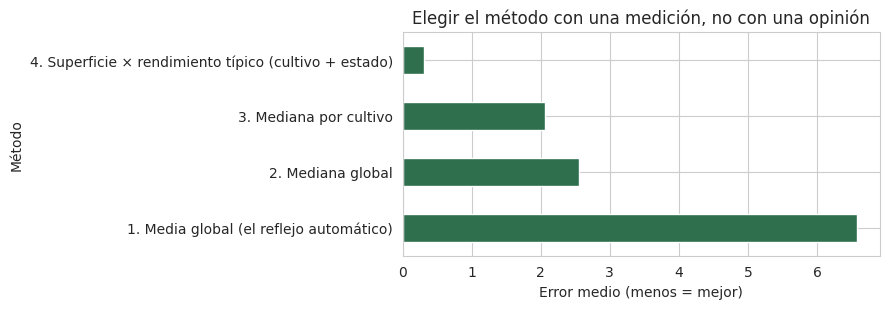

In [11]:
df["Rendimiento"] = df.Produccion_ton / df.Area_ha
conocidas = df[df.Produccion_ton.notna() & (df.Produccion_ton > 0)]
tapadas = conocidas.sample(frac=0.05, random_state=SEED)               # tapamos el 5 % al azar
base = conocidas.drop(tapadas.index)                                   # lo que el método "puede ver"
verdad = tapadas.Produccion_ton

media_global = base.Produccion_ton.mean()
mediana_global = base.Produccion_ton.median()
med_cultivo = base.groupby("Cultivo").Produccion_ton.median()
rend_tipico = base.groupby(["Cultivo", "Estado"]).Rendimiento.median()
rend_tipico_idx = pd.MultiIndex.from_frame(tapadas[["Cultivo", "Estado"]]).map(rend_tipico)

metodos = {
    "1. Media global (el reflejo automático)": np.full(len(tapadas), media_global),
    "2. Mediana global": np.full(len(tapadas), mediana_global),
    "3. Mediana por cultivo": tapadas.Cultivo.map(med_cultivo).values,
    "4. Superficie × rendimiento típico (cultivo + estado)": tapadas.Area_ha.values * np.asarray(rend_tipico_idx),
}
filas = []
for nombre, pred in metodos.items():
    pred = pd.Series(pred, index=verdad.index).fillna(mediana_global)
    err_log = np.abs(np.log1p(pred) - np.log1p(verdad))
    filas.append({"Método": nombre, "Error (escala log)": err_log.mean(),
                  "Error mediano %": (np.abs(pred - verdad) / verdad).median() * 100})
res = pd.DataFrame(filas).set_index("Método").sort_values("Error (escala log)")
display(res)

res["Error (escala log)"].iloc[::-1].plot.barh(figsize=(9, 3.2), color="#2f6f4e")
plt.xlabel("Error medio (menos = mejor)"); plt.title("Elegir el método con una medición, no con una opinión"); plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>La <b>media global</b> (lo que haría casi cualquiera por reflejo) es <b>la peor por muchísimo</b>. Cada capa de contexto que agregamos reduce el error, y el ganador usa <b>razonamiento agronómico</b>: <i>producción = superficie × rendimiento que es típico de ese cultivo en ese estado</i>. Un método simple, con sentido del dominio, le gana a uno complicado sin él.</div>

In [12]:
# Se aplica el método ganador
pos = df.Produccion_ton > 0
rend_ref = df[pos].groupby(["Cultivo", "Estado"]).Rendimiento.median()       # 1.ª opción: ese cultivo en ese estado
rend_cult = df[pos].groupby("Cultivo").Rendimiento.median()                  # 2.ª opción: ese cultivo en todo el país
est = pd.Series(np.asarray(pd.MultiIndex.from_frame(df.loc[df.falta, ["Cultivo", "Estado"]]).map(rend_ref)),
                index=df.index[df.falta])
est = est.fillna(df.loc[df.falta, "Cultivo"].map(rend_cult))
df["produccion_imputada"] = False
df.loc[df.falta, "Produccion_ton"] = df.loc[df.falta, "Area_ha"] * est
df.loc[df.falta & df.Produccion_ton.notna(), "produccion_imputada"] = True

sin_ref = df.Produccion_ton.isna().sum()
n0 = len(df)
df = df[df.Produccion_ton.notna()].copy()               # sin referencia no se inventa: se descarta
anotar("5. Faltantes", "producción = superficie × rendimiento típico (cultivo+estado, o solo cultivo); sin referencia se descarta",
       n0, len(df), int(df.produccion_imputada.sum()) + sin_ref)
print(f"Valores estimados (marcados con bandera): {df.produccion_imputada.sum():,}")
print(f"Filas sin referencia posible (descartadas): {sin_ref}")
df = df.drop(columns=["falta", "cuartil_area"])

Valores estimados (marcados con bandera): 3,688
Filas sin referencia posible (descartadas): 42


<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br>Todo valor estimado queda <b>marcado</b> con la columna <code>produccion_imputada</code>. Así, nadie confunde después un dato <i>medido</i> con uno <i>estimado</i>, y se pueden excluir de los análisis delicados (en la Parte 5 del notebook principal los excluimos al modelar).</div>

### 6️⃣ Ceros sospechosos · 7️⃣ Unidades mezcladas · 8️⃣ Rendimiento

6) Producción = 0 con superficie sembrada: 3,510 filas → se MARCAN
   (un cero puede ser real: sequía, granizo, cosecha perdida. No se borra.)



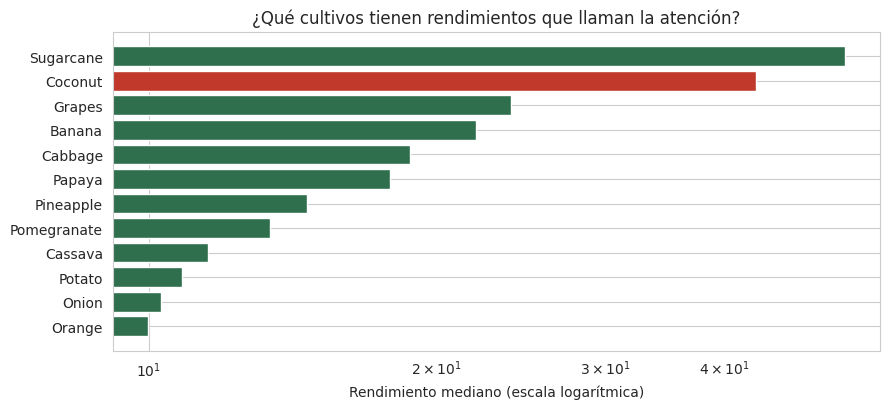

Rendimiento mediano — Coconut: 43.1 | Arecanut: 1.24 | Cashewnut: 0.39 | Rice: 1.93


In [13]:
# 6) Producción = 0 con superficie > 0
df["produccion_nula_reportada"] = (df.Produccion_ton == 0) & (df.Area_ha > 0)
print(f"6) Producción = 0 con superficie sembrada: {df.produccion_nula_reportada.sum():,} filas → se MARCAN")
print("   (un cero puede ser real: sequía, granizo, cosecha perdida. No se borra.)\n")

# 8) Rendimiento = producción / superficie  (comparable entre distritos de distinto tamaño)
df["Rendimiento"] = df.Produccion_ton / df.Area_ha

# 7) Unidades: miramos la mediana de rendimiento por cultivo
med = df[~df.produccion_nula_reportada].groupby("Cultivo").Rendimiento.median().sort_values(ascending=False)
top = med.head(12)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(top.index[::-1], top.values[::-1], color=["#c0392b" if c == "Coconut" else "#2f6f4e" for c in top.index[::-1]])
ax.set_xscale("log"); ax.set_xlabel("Rendimiento mediano (escala logarítmica)")
ax.set_title("¿Qué cultivos tienen rendimientos que llaman la atención?"); plt.tight_layout(); plt.show()
print("Rendimiento mediano — Coconut:", round(med["Coconut"], 1), "| Arecanut:", round(med["Arecanut"], 2),
      "| Cashewnut:", round(med["Cashewnut"], 2), "| Rice:", round(med["Rice"], 2))

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>El <b>coco</b> aparece con un rendimiento absurdo en comparación con los demás cultivos de la tabla. La explicación: el coco se registra en <b>cantidad de frutos</b> (unidades), no en toneladas, aunque la columna se llama "producción en toneladas". Es el mismo número de columna pero <b>distinta unidad</b>. En la Etapa 1-B también se marcaron el <i>arecanut</i> y el <i>cashewnut</i>.
<br><br>No son errores de carga: son <b>unidades incompatibles</b> en la misma columna. Se <b>marcan</b> (no se borran) y se excluyen solo de los promedios de rendimiento.</div>

In [14]:
UNIDAD_DISTINTA = ["Coconut", "Arecanut", "Cashewnut"]            # decisión de dominio (Etapa 1-B)
df["unidad_comparable"] = ~df.Cultivo.isin(UNIDAD_DISTINTA)
anotar("6-8. Banderas", "ceros marcados, unidades distintas marcadas, Rendimiento creado", len(df), len(df),
       int(df.produccion_nula_reportada.sum() + (~df.unidad_comparable).sum()))
print("Filas con unidad no comparable:", (~df.unidad_comparable).sum())

Filas con unidad no comparable: 4725


### 9️⃣ La bitácora y la comparación con tu limpieza de la Etapa 1-B

In [15]:
bit = pd.DataFrame(bitacora).set_index("Paso")
display(bit)
print(f"\nDe {len(raw):,} filas originales quedan {len(df):,} ({len(df)/len(raw):.1%}).")

,Qué se hizo,Filas antes,Filas después,Afectadas (celdas/filas)
Paso,,,,
1. Espacios,strip() y espacios dobles en 4 columnas de texto,246091,246091,258550
2. Nombres,diccionario de 17 typos/sinónimos,246091,246091,49059
3. Totales,"se eliminan filas 'Pulses total', 'Oilseeds to...",246091,245211,880
4. Duplicados,se eliminan duplicados exactos surgidos al uni...,245211,244886,325
5. Faltantes,producción = superficie × rendimiento típico (...,244886,244844,3730
6-8. Banderas,"ceros marcados, unidades distintas marcadas, R...",244844,244844,8235



De 246,091 filas originales quedan 244,844 (99.5%).


In [16]:
# ¿Coincide con la limpieza de la Etapa 1-B?
RUTA_E1B = ruta("crop_production_LIMPIO.csv", obligatorio=False)      # opcional: el limpio ORIGINAL de la Etapa 1-B
if RUTA_E1B is not None:
    e1b = pd.read_csv(RUTA_E1B)
    print(f"Filas  Etapa 1-B: {len(e1b):,}  |  Filas este taller: {len(df):,}  |  Diferencia: {len(e1b) - len(df):,}")
    dup1b = e1b.duplicated().sum()
    print(f"Duplicados exactos en el LIMPIO de la Etapa 1-B: {dup1b}")
    print("→ La diferencia son los duplicados de arroz (Paddy/Rice) que esta limpieza detectó y eliminó." if len(e1b) - len(df) == dup1b else "")
df.to_csv(SALIDA / "crop_production_limpio_express.csv", index=False)
print("Guardado: salida/crop_production_limpio_express.csv")

Filas  Etapa 1-B: 245,169  |  Filas este taller: 244,844  |  Diferencia: 325
Duplicados exactos en el LIMPIO de la Etapa 1-B: 325
→ La diferencia son los duplicados de arroz (Paddy/Rice) que esta limpieza detectó y eliminó.


Guardado: crop_production_limpio_express.csv


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Las dos limpiezas coinciden en todo, salvo en <b>los duplicados de arroz</b>: esta versión los detectó al revisar duplicados <i>después</i> de unificar nombres. Para el modelado el impacto es chico (≈0,13 % de las filas), pero en la superficie arrocera de Assam era <b>el doble</b>. <b>Conviene regenerar <code>crop_production_LIMPIO.csv</code></b> con este paso extra.</div>

### 🔟 Traducción al castellano (para analizar mejor)

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Las limpiezas anteriores se hicieron sobre el texto <b>original en inglés</b>, porque ahí estaban los typos que había que arreglar (<code>Pome Granet</code>, <code>Pump Kin</code>…). Ahora que el dato está limpio, <b>lo traducimos</b> y guardamos una versión en castellano. Además de los cultivos traducimos las <b>temporadas</b>: <b>Kharif</b> es la campaña de verano que se siembra con las lluvias del monzón (junio–julio) y <b>Rabi</b> la de invierno-primavera (octubre–noviembre).</div>

In [17]:
CULT_B = {'Apple': 'Manzana',
 'Arecanut': 'Nuez de areca',
 'Ash Gourd': 'Calabaza cerosa',
 'Banana': 'Banana',
 'Barley': 'Cebada',
 'Bean': 'Poroto',
 'Beans & Mutter(Vegetable)': 'Porotos y arvejas (hortaliza)',
 'Beet Root': 'Remolacha',
 'Ber': 'Ber (azufaifo)',
 'Bitter Gourd': 'Melón amargo',
 'Black pepper': 'Pimienta negra',
 'Blackgram': 'Poroto negro',
 'Bottle Gourd': 'Calabaza botella',
 'Brinjal': 'Berenjena',
 'Cabbage': 'Repollo',
 'Cardamom': 'Cardamomo',
 'Carrot': 'Zanahoria',
 'Cashewnut': 'Castaña de cajú',
 'Cassava': 'Mandioca',
 'Castor seed': 'Semilla de ricino',
 'Cauliflower': 'Coliflor',
 'Chickpea': 'Garbanzo',
 'Citrus Fruit': 'Cítricos',
 'Coconut': 'Coco',
 'Coffee': 'Café',
 'Colocosia': 'Colocasia (taro)',
 'Cond-spcs other': 'Condimentos y especias (otros)',
 'Coriander': 'Cilantro',
 'Cotton': 'Algodón',
 'Cowpea(Lobia)': 'Caupí',
 'Cucumber': 'Pepino',
 'Drum Stick': 'Moringa',
 'Dry chillies': 'Ají seco',
 'Dry ginger': 'Jengibre seco',
 'Garlic': 'Ajo',
 'Ginger': 'Jengibre',
 'Grapes': 'Uva',
 'Groundnut': 'Maní',
 'Guar seed': 'Semilla de guar',
 'Horse-gram': 'Poroto de caballo',
 'Jack Fruit': 'Yaca',
 'Jobster': 'Jobster (nombre dudoso)',
 'Jute': 'Yute',
 'Jute & mesta': 'Yute y mesta',
 'Khesari': 'Khesari (almorta)',
 'Korra': 'Korra (mijo cola de zorra)',
 'Lab-Lab': 'Poroto jacinto',
 'Lemon': 'Limón',
 'Lentil': 'Lenteja',
 'Linseed': 'Lino (linaza)',
 'Litchi': 'Lichi',
 'Maize': 'Maíz',
 'Mango': 'Mango',
 'Mesta': 'Mesta (fibra)',
 'Moth': 'Poroto moth',
 'Mungbean': 'Poroto mung',
 'Niger seed': 'Semilla de niger',
 'Okra': 'Okra (quimbombó)',
 'Onion': 'Cebolla',
 'Orange': 'Naranja',
 'Other Cereals & Millets': 'Otros cereales y mijos',
 'Other Citrus Fruit': 'Otros cítricos',
 'Other Dry Fruit': 'Otros frutos secos',
 'Other Fresh Fruits': 'Otras frutas frescas',
 'Other Kharif pulses': 'Otras legumbres Kharif',
 'Other Rabi pulses': 'Otras legumbres Rabi',
 'Other Vegetables': 'Otras hortalizas',
 'Papaya': 'Papaya',
 'Peach': 'Durazno',
 'Pear': 'Pera',
 'Pearl Millet': 'Mijo perla',
 'Peas & beans (Pulses)': 'Arvejas y porotos (legumbre)',
 'Peas (vegetable)': 'Arvejas (hortaliza)',
 'Perilla': 'Perilla',
 'Pigeonpeas': 'Gandul',
 'Pineapple': 'Ananá',
 'Plums': 'Ciruela',
 'Pome Fruit': 'Frutas de pepita',
 'Pomegranate': 'Granada',
 'Potato': 'Papa',
 'Pumpkin': 'Zapallo',
 'Ragi': 'Ragi (mijo africano)',
 'Rajmash Kholar': 'Rajmash (poroto rojo)',
 'Rapeseed &Mustard': 'Colza y mostaza',
 'Redish': 'Rábano',
 'Ribed Guard': 'Calabaza acanalada',
 'Rice': 'Arroz',
 'Ricebean (nagadal)': 'Poroto arroz',
 'Rubber': 'Caucho',
 'Safflower': 'Cártamo',
 'Samai': 'Samai (mijo menor)',
 'Sannhamp': 'Cáñamo sunn',
 'Sapota': 'Sapote',
 'Sesamum': 'Sésamo',
 'Small millets': 'Mijos menores',
 'Snak Guard': 'Calabaza serpiente',
 'Sorghum': 'Sorgo',
 'Soyabean': 'Soja',
 'Sugarcane': 'Caña de azúcar',
 'Sunflower': 'Girasol',
 'Sweet potato': 'Batata',
 'Tea': 'Té',
 'Tobacco': 'Tabaco',
 'Tomato': 'Tomate',
 'Turmeric': 'Cúrcuma',
 'Turnip': 'Nabo',
 'Urad': 'Urad',
 'Varagu': 'Varagu (mijo kodo)',
 'Water Melon': 'Sandía',
 'Wheat': 'Trigo',
 'Yam': 'Ñame',
 'other fibres': 'Otras fibras',
 'other misc. pulses': 'Otras legumbres varias',
 'other oilseeds': 'Otras oleaginosas'}

TEMPORADA = {'Autumn': 'Otoño',
 'Kharif': 'Kharif (monzón)',
 'Rabi': 'Rabi (invierno)',
 'Summer': 'Verano',
 'Whole Year': 'Todo el año',
 'Winter': 'Invierno'}

ESTADO = {'Andaman and Nicobar Islands': 'Islas Andamán y Nicobar',
 'Dadra and Nagar Haveli': 'Dadra y Nagar Haveli',
 'Jammu and Kashmir': 'Jammu y Cachemira',
 'West Bengal': 'Bengala Occidental'}

df_es = df.copy()
df_es["Cultivo"] = df_es.Cultivo.map(CULT_B); df_es["Temporada"] = df_es.Temporada.map(TEMPORADA); df_es["Estado"] = df_es.Estado.replace(ESTADO)
assert df_es.Cultivo.notna().all() and df_es.Temporada.notna().all(), "Hay valores sin traducir"
df_es.to_csv(SALIDA / "crop_production_limpio_castellano.csv", index=False)
print("Guardado: salida/crop_production_limpio_castellano.csv")
df_es[["Estado", "Cultivo", "Temporada", "Anio", "Area_ha", "Produccion_ton", "Rendimiento"]].sample(6, random_state=SEED)

Guardado: crop_production_limpio_castellano.csv


,Estado,Cultivo,Temporada,Anio,Area_ha,Produccion_ton,Rendimiento
72790,Himachal Pradesh,Lino (linaza),Rabi (invierno),1998,341.000,36.000,0.106
241112,Bengala Occidental,Nuez de areca,Todo el año,2008,405.000,542.000,1.338
225173,Uttar Pradesh,Papa,Rabi (invierno),2010,"6,087.000","124,728.000",20.491
246076,Bengala Occidental,Lino (linaza),Rabi (invierno),2014,160.000,51.000,0.319
169091,Rajasthan,Otras legumbres Kharif,Kharif (monzón),2009,73.000,7.000,0.096
125639,Maharashtra,Maní,Kharif (monzón),2013,"4,700.000","3,700.000",0.787


#### 🎬 ¿Por qué todo esto importa? Mismo análisis, con y sin limpieza

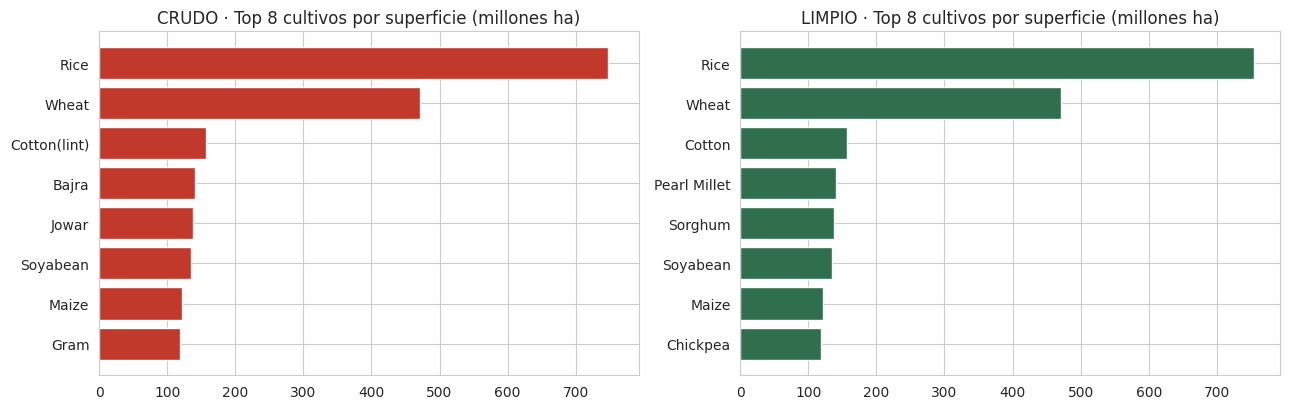

Crudo : ['Rice', 'Wheat', 'Cotton(lint)', 'Bajra', 'Jowar', 'Soyabean', 'Maize', 'Gram']
Limpio: ['Rice', 'Wheat', 'Cotton', 'Pearl Millet', 'Sorghum', 'Soyabean', 'Maize', 'Chickpea']


In [18]:
sucio = raw.rename(columns=TRADUCCION)
sucio["Cultivo"] = sucio.Cultivo.str.strip()
a = sucio.groupby("Cultivo").Area_ha.sum().sort_values(ascending=False).head(8) / 1e6
b = df.groupby("Cultivo").Area_ha.sum().sort_values(ascending=False).head(8) / 1e6

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
ax[0].barh(a.index[::-1], a.values[::-1], color="#c0392b"); ax[0].set_title("CRUDO · Top 8 cultivos por superficie (millones ha)")
ax[1].barh(b.index[::-1], b.values[::-1], color="#2f6f4e"); ax[1].set_title("LIMPIO · Top 8 cultivos por superficie (millones ha)")
plt.tight_layout(); plt.show()
print("Crudo :", list(a.index)); print("Limpio:", list(b.index))

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>En el crudo, <b>la lista de "cultivos más sembrados" está llena de sinónimos</b> (<code>Cotton(lint)</code>, <code>Bajra</code>, <code>Jowar</code>…) y el arroz aparece <b>partido en dos</b> (<code>Rice</code> y <code>Paddy</code>). Un análisis hecho sobre el crudo daría conclusiones incorrectas <i>sin ningún mensaje de error</i>. Esa es la razón de ser de la limpieza.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte B</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Practicá con un set chico: el Titanic</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">891 pasajeros reales con edades que faltan, cabinas que faltan y texto útil escondido</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>El dataset del Titanic es el "cuaderno de práctica" clásico de la ciencia de datos porque es <b>chico, real y sucio</b>. Acá nos concentramos en <b>una sola habilidad</b>: qué hacer cuando <b>faltan valores</b>, y cómo se elige con una medición. El archivo viene en inglés: lo <b>traducimos al castellano</b> al cargarlo.</div>

In [19]:
TITANIC_COLS = {'PassengerId': 'IdPasajero',
 'Survived': 'Sobrevivio',
 'Pclass': 'Clase',
 'Name': 'Nombre',
 'Sex': 'Sexo',
 'Age': 'Edad',
 'SibSp': 'Hermanos_Conyuge',
 'Parch': 'Padres_Hijos',
 'Ticket': 'Boleto',
 'Fare': 'Tarifa',
 'Cabin': 'Cabina',
 'Embarked': 'Puerto_Embarque'}

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
try:
    ti = pd.read_csv(URL); ok_titanic = True
except Exception as e:
    print("No se pudo descargar (¿sin internet?):", type(e).__name__); ok_titanic = False

if ok_titanic:
    ti = ti.rename(columns=TITANIC_COLS)                                                   # columnas en castellano
    ti["Sexo"] = ti.Sexo.map({"male": "hombre", "female": "mujer"})                        # valores en castellano
    ti["Puerto_Embarque"] = ti.Puerto_Embarque.map({"S": "Southampton", "C": "Cherburgo", "Q": "Queenstown"})
    auditar(ti, "Titanic (crudo, traducido)"); display(ti.head(3))

📋 Titanic (crudo, traducido): 891 filas × 12 columnas
   Filas duplicadas exactas : 0
   Columnas con nulos       : {'Edad': '177 (19.9%)', 'Cabina': '687 (77.1%)', 'Puerto_Embarque': '2 (0.2%)'}
   ⚠️ 'Nombre': 2 valores con espacios al inicio/final
   Columnas con negativos   : ninguna


,IdPasajero,Sobrevivio,Clase,Nombre,Sexo,Edad,Hermanos_Conyuge,Padres_Hijos,Boleto,Tarifa,Cabina,Puerto_Embarque
0,1,0,3,"Braund, Mr. Owen Harris",hombre,22.000,1,0,A/5 21171,7.250,NaN,Southampton
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",mujer,38.000,1,0,PC 17599,71.283,C85,Cherburgo
2,3,1,3,"Heikkinen, Miss. Laina",mujer,26.000,0,0,STON/O2. 3101282,7.925,NaN,Southampton


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Glosario de columnas:</b> <code>Sobrevivio</code> (1 = sí, 0 = no) · <code>Clase</code> (1.ª, 2.ª o 3.ª) · <code>Hermanos_Conyuge</code> (hermanos o cónyuge a bordo) · <code>Padres_Hijos</code> (padres o hijos a bordo) · <code>Boleto</code> (número de ticket) · <code>Tarifa</code> (lo que pagó) · <code>Cabina</code> (número de camarote) · <code>Puerto_Embarque</code> (dónde subió).</div>

In [20]:
if ok_titanic:
    print("% de faltantes por columna:"); print((ti.isna().mean()[ti.isna().any()] * 100).round(1).astype(str) + " %")
    ti["edad_falta"] = ti.Edad.isna()
    print("\nTasa de supervivencia según si falta la edad:")
    print((ti.groupby("edad_falta").Sobrevivio.mean() * 100).round(1).astype(str) + " %")
    print("\nDistribución por clase de los que NO tienen edad:")
    print((ti[ti.edad_falta].Clase.value_counts(normalize=True).sort_index() * 100).round(0).astype(str) + " %")

% de faltantes por columna:
Edad               19.9 %
Cabina             77.1 %
Puerto_Embarque     0.2 %
dtype: str

Tasa de supervivencia según si falta la edad:
edad_falta
False    40.6 %
True     29.4 %
Name: Sobrevivio, dtype: str

Distribución por clase de los que NO tienen edad:
Clase
1    17.0 %
2     6.0 %
3    77.0 %
Name: proportion, dtype: str


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Los pasajeros <b>sin edad no son una muestra al azar</b>: se concentran en <b>3.ª clase</b> y tienen <b>otra tasa de supervivencia</b>. Si borráramos esas filas (<code>dropna()</code>), el dataset resultante estaría <b>sesgado</b> hacia las clases altas. Es MAR otra vez: dependen de la clase (variable observada). Mejor <b>completar con criterio</b>.</div>

#### ¿Qué edad ponemos? Mismo experimento: tapar edades conocidas y ver quién adivina mejor

Títulos extraídos del nombre: {'Sr': 517, 'Srta': 185, 'Sra': 126, 'Niño': 40, 'Otro': 23}


,Error medio (años)
"4. Mediana por TÍTULO (Sr, Sra, Srta, Niño)",8.138
2. Mediana por clase,9.607
3. Mediana por clase + sexo,9.705
1. Media global,10.735


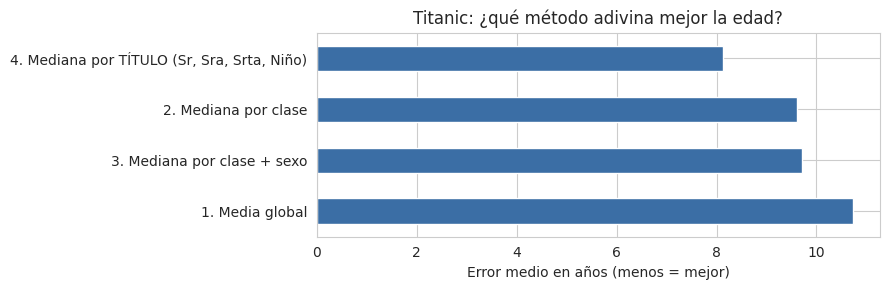

In [21]:
if ok_titanic:
    # El nombre trae el título ("Braund, Mr. Owen Harris"): texto útil escondido
    ti["Titulo"] = ti.Nombre.str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    ti["Titulo"] = ti.Titulo.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    ti["Titulo"] = ti.Titulo.where(ti.Titulo.isin(["Mr", "Mrs", "Miss", "Master"]), "Otro")
    ti["Titulo"] = ti.Titulo.map({"Mr": "Sr", "Mrs": "Sra", "Miss": "Srta", "Master": "Niño", "Otro": "Otro"})   # en castellano
    print("Títulos extraídos del nombre:", ti.Titulo.value_counts().to_dict())

    conocidas = ti[ti.Edad.notna()]
    tap = conocidas.sample(frac=0.25, random_state=SEED); vis = conocidas.drop(tap.index)
    def evaluar(pred): return float(np.abs(pred - tap.Edad).mean())
    res = {
        "1. Media global": evaluar(vis.Edad.mean()),
        "2. Mediana por clase": evaluar(tap.Clase.map(vis.groupby("Clase").Edad.median())),
        "3. Mediana por clase + sexo": evaluar(pd.MultiIndex.from_frame(tap[["Clase", "Sexo"]]).map(vis.groupby(["Clase", "Sexo"]).Edad.median())),
        "4. Mediana por TÍTULO (Sr, Sra, Srta, Niño)": evaluar(tap.Titulo.map(vis.groupby("Titulo").Edad.median())),
    }
    r = pd.Series(res, name="Error medio (años)").sort_values().to_frame(); display(r)
    r["Error medio (años)"].iloc[::-1].plot.barh(figsize=(9, 3), color="#3b6ea5"); plt.xlabel("Error medio en años (menos = mejor)")
    plt.title("Titanic: ¿qué método adivina mejor la edad?"); plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>El mejor método usa el <b>título del nombre</b> (<i>Niño</i> = <i>Master</i> en el original, un varón joven; <i>Srta</i> = <i>Miss</i>; <i>Sr</i> = <i>Mr</i>…). Es información <b>escondida en una columna de texto que a primera vista parece inútil</b>. Moraleja: antes de descartar una columna "sucia", fijate si tiene algo valioso adentro.</div>

In [22]:
if ok_titanic:
    # Limpieza final: cada columna con su criterio
    t = ti.copy()
    t["Edad"] = t.Edad.fillna(t.Titulo.map(t.groupby("Titulo").Edad.median()))          # edad: mediana por título
    t["tiene_cabina"] = t.Cabina.notna().astype(int)                                     # 77 % falta → se convierte en señal (sí/no)
    t["Puerto_Embarque"] = t.Puerto_Embarque.fillna(t.Puerto_Embarque.mode()[0])         # 2 faltantes → la moda
    t = t.drop(columns=["Cabina", "Nombre", "Boleto", "IdPasajero"])
    t["Sexo"] = (t.Sexo == "mujer").astype(int)
    t = pd.get_dummies(t, columns=["Puerto_Embarque", "Titulo"], drop_first=True)
    print("Nulos que quedan:", int(t.drop(columns="edad_falta").isna().sum().sum()), "| filas:", len(t), "(no perdimos ninguna)")
    print("Supervivencia: con cabina →", f"{t[t.tiene_cabina==1].Sobrevivio.mean():.0%}", "| sin cabina →", f"{t[t.tiene_cabina==0].Sobrevivio.mean():.0%}")

Nulos que quedan: 0 | filas: 891 (no perdimos ninguna)
Supervivencia: con cabina → 67% | sin cabina → 30%


In [23]:
if ok_titanic:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import cross_val_score, StratifiedKFold
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    X, y = t.drop(columns=["Sobrevivio", "edad_falta"]), t.Sobrevivio
    rf = RandomForestClassifier(300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
    acc = cross_val_score(rf, X, y, cv=cv).mean()
    azar = max(y.mean(), 1 - y.mean())
    print(f"Con los datos limpios, un Random Forest acierta {acc:.1%} (siempre decir 'no sobrevivió' daría {azar:.1%}).")

Con los datos limpios, un Random Forest acierta 83.9% (siempre decir 'no sobrevivió' daría 61.6%).


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Lo que mostró la Parte B:</b> (1) investigar <i>por qué</i> faltan los datos antes de decidir; (2) <b>no borrar filas</b> si se puede completar con criterio; (3) elegir el método de relleno <b>midiendo</b> con valores tapados; (4) una columna con muchos faltantes (<i>Cabina</i>) puede convertirse en una señal útil (<i>tiene / no tiene</i>); (5) el texto "sucio" puede guardar información valiosa.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Cierre</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Checklist para limpiar cualquier dataset</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Guardalo: sirve para todos tus proyectos</div></div>

- [ ] **No tocar el original.** Trabajar sobre una copia.
- [ ] **Auditar primero** (`auditar(df)`): duplicados, nulos, espacios, negativos.
- [ ] **Texto antes que todo:** `strip()`, espacios dobles, mayúsculas/minúsculas.
- [ ] **Nombres:** buscar typos y sinónimos; unificar con un **diccionario** (decisión humana).
- [ ] **Filas que no son datos:** totales, subtotales, encabezados repetidos.
- [ ] **Duplicados:** revisarlos **al final de cada paso** que unifique valores.
- [ ] **Faltantes:** ¿MCAR, MAR o MNAR? Elegir el método **midiendo** con valores tapados.
- [ ] **Valores raros** (ceros, extremos): entender el motivo antes de borrar. Ante la duda: **bandera**, no borrado.
- [ ] **Unidades:** ¿todas las filas de una columna miden lo mismo?
- [ ] **Marcar todo lo que se estimó o modificó** para que sea trazable.
- [ ] **Bitácora:** cuántas filas antes y después de cada paso.

> 🧠 **Idea final:** la limpieza no es "arreglar errores": es **tomar decisiones y dejarlas documentadas**. Dos personas pueden limpiar el mismo archivo de forma distinta; lo que hace buena a una limpieza es que cada decisión esté **justificada y medida**.